
# Practical Work 7 — Decision Tree, Random Forest and SHAP

**Project:** MACHINEGUARD  
**Level:** C

## Objective

To compare Decision Tree and Random Forest models for machine failure prediction, analyze feature importance using two methods, and explain individual predictions using SHAP.

## Dataset

AI4I 2020 Predictive Maintenance Dataset.

Source: https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("MACHINEGUARD PR7")
print("All libraries imported successfully!")


MACHINEGUARD PR7
All libraries imported successfully!


In [2]:

project_dir = Path.cwd().resolve()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

df = pd.read_csv(
    project_dir / "data" / "raw" / "ai4i2020.csv"
)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:

features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = pd.get_dummies(
    df[features],
    columns=["Type"],
    dtype=int
)

y = df["Machine failure"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Failure distribution:")
print(y.value_counts())


Training shape: (8000, 8)
Testing shape: (2000, 8)
Failure distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


In [4]:

decision_tree = DecisionTreeClassifier(
    max_depth=6,
    class_weight="balanced",
    random_state=42
)

random_forest = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

decision_tree.fit(X_train, y_train)
random_forest.fit(X_train, y_train)

print("Decision Tree trained successfully!")
print("Random Forest trained successfully!")


Decision Tree trained successfully!
Random Forest trained successfully!


In [5]:

models = {
    "Decision Tree": decision_tree,
    "Random Forest": random_forest
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1
0,Decision Tree,0.9365,0.3314,0.8529,0.4774
1,Random Forest,0.9665,0.5050,0.7500,0.6036


              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1932
           1       0.50      0.75      0.60        68

    accuracy                           0.97      2000
   macro avg       0.75      0.86      0.79      2000
weighted avg       0.97      0.97      0.97      2000



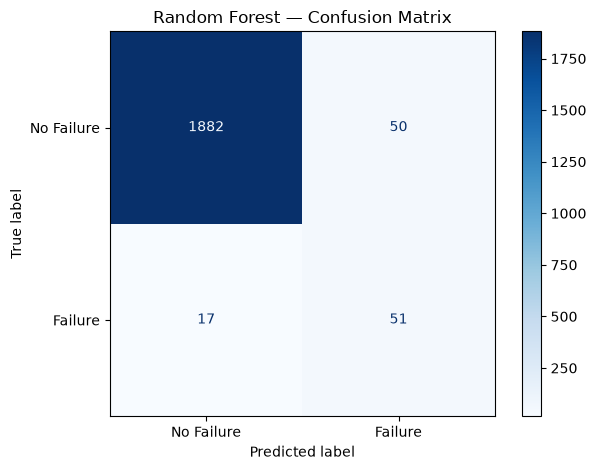

In [6]:

predictions = random_forest.predict(X_test)

print(classification_report(
    y_test,
    predictions,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=["No Failure", "Failure"],
    cmap="Blues"
)

plt.title("Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()


,Feature,Importance
2,Rotational speed [rpm],0.316812
3,Torque [Nm],0.308111
4,Tool wear [min],0.208360
0,Air temperature [K],0.086161
1,Process temperature [K],0.063106
6,Type_L,0.008388
7,Type_M,0.005950
5,Type_H,0.003112


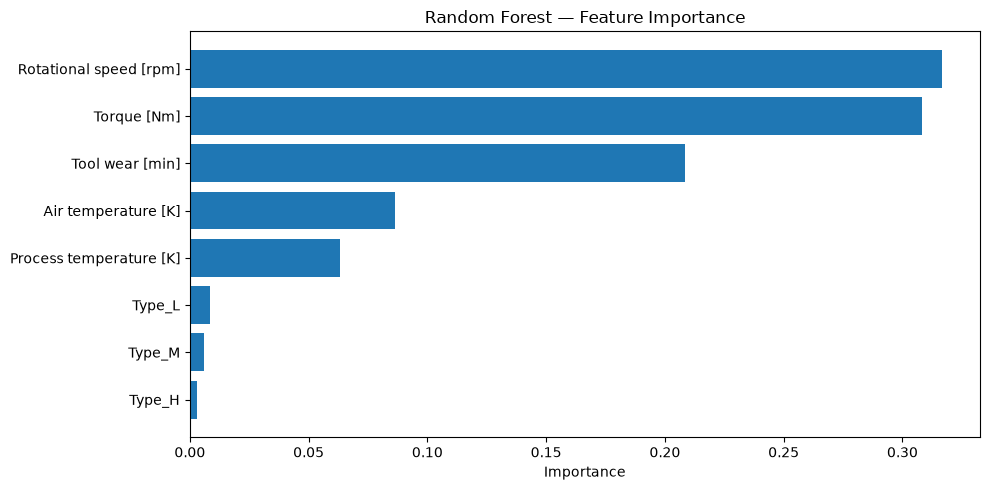

In [7]:

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(10, 5))

plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1]
)

plt.title("Random Forest — Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


,Feature,Permutation Importance
3,Torque [Nm],0.283682
2,Rotational speed [rpm],0.267276
4,Tool wear [min],0.122157
0,Air temperature [K],0.120214
1,Process temperature [K],0.038887
6,Type_L,0.022228
5,Type_H,-0.005369
7,Type_M,-0.009476


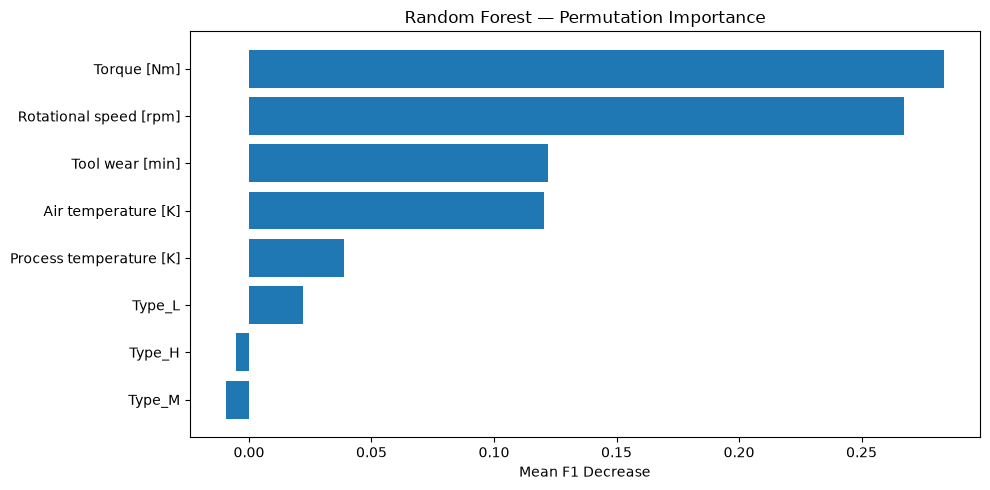

In [8]:

perm_result = permutation_importance(
    random_forest,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="f1",
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X.columns,
    "Permutation Importance": perm_result.importances_mean
}).sort_values(
    "Permutation Importance",
    ascending=False
)

display(permutation_df)

plt.figure(figsize=(10, 5))

plt.barh(
    permutation_df["Feature"][::-1],
    permutation_df["Permutation Importance"][::-1]
)

plt.title("Random Forest — Permutation Importance")
plt.xlabel("Mean F1 Decrease")
plt.tight_layout()
plt.show()


In [9]:

# Use a small sample to keep calculations fast
X_shap = X_test.sample(n=100, random_state=42)

explainer = shap.TreeExplainer(random_forest)
shap_values = explainer(X_shap)

print("SHAP values shape:", shap_values.values.shape)
print("SHAP calculation completed!")


SHAP values shape: (100, 8, 2)
SHAP calculation completed!


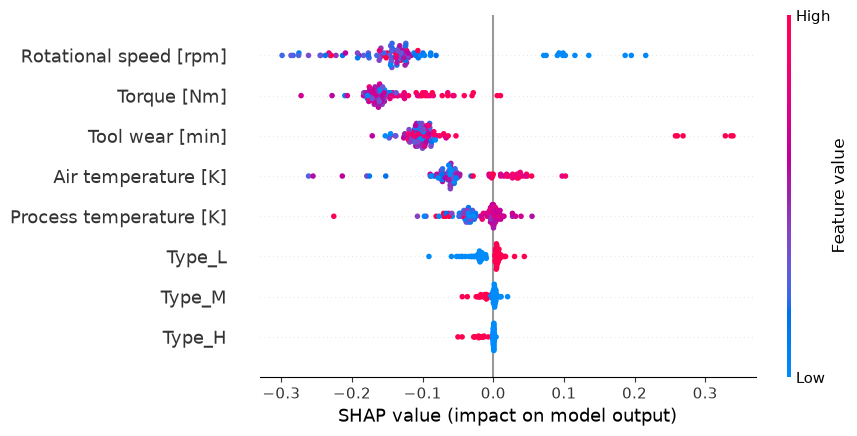

In [10]:

# Select SHAP values for failure class
failure_shap = shap_values[:, :, 1]

shap.plots.beeswarm(
    failure_shap,
    max_display=8,
    show=True
)


Actual class: 0
Predicted failure probability: 0.016


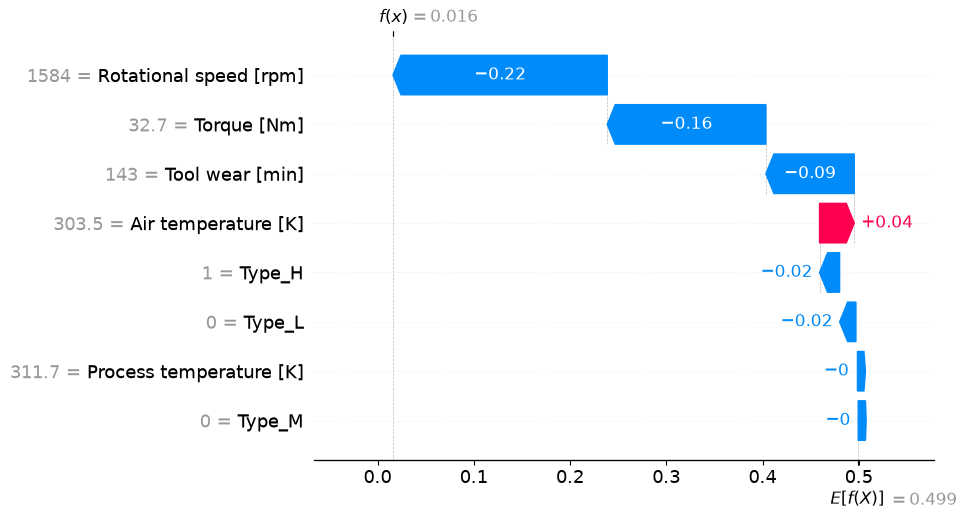

In [11]:

sample_index = 0

print("Actual class:", y_test.loc[X_shap.index[sample_index]])
print(
    "Predicted failure probability:",
    round(
        random_forest.predict_proba(
            X_shap.iloc[[sample_index]]
        )[0, 1],
        4
    )
)

shap.plots.waterfall(
    failure_shap[sample_index],
    max_display=8,
    show=True
)



## Results and Discussion

### Model Comparison

Decision Tree and Random Forest classifiers were trained using the same dataset and train/test split.

The models were evaluated using accuracy, precision, recall, and F1-score.

Due to the imbalance of machine failure classes, recall and F1-score are particularly important for evaluating minority-class predictions.

### Feature Importance

Random Forest feature importance was used to identify influential machine operating parameters.

Permutation importance provided an additional evaluation by measuring the decrease in F1-score after randomly shuffling individual features.

Differences between these methods can occur because impurity-based importance measures how features contribute to tree splits, while permutation importance measures their effect on predictive performance.

### SHAP Analysis

SHAP was used to interpret Random Forest predictions.

The beeswarm plot visualized the influence of features across multiple observations.

The waterfall plot explained how individual feature values contributed to a specific machine failure prediction.

### Conclusion

Practical Work 7 demonstrated the use of Decision Tree and Random Forest algorithms for predictive maintenance.

The experiment compared classification performance and investigated feature importance using multiple interpretation techniques.

SHAP analysis provided explanations for individual predictions, supporting a better understanding of the machine learning model.
